# League of Legends Match Data Exploration

### Data Dictionary

| Table & Column | Statistical classification                                                             | Meaning                                                                  |
|---|----------------------------------------------------------------------------------------|--------------------------------------------------------------------------|
| `MatchStatsId`, `MatchId` | ID's                                                                                   | Unique record / match identifier                                         |
| `GameDuration` | Numerical measurement                                                                  | Match length, measured in seconds                                        |
| `TotalGold` | Numerical count                                                                        | Gold earned by the player                                                |
| `DmgDealt`, `DmgTaken` | Numerical count                                                                        | Damage dealt to / taken from champions                                   |
| `MinionsKilled` | Numerical count                                                                        | equals 0 in non-laning modes or for supports.                            |
| `kills`, `deaths`, `assists` | Numerical counts                                                                       | summarizes combat participation.                                         |
| `Lane` | Unordered category                                                                     | `TOP`, `JUNGLE`, `MIDDLE`, `BOTTOM`, `NONE`                              |
| `ChampionFk`, `item1`–`item6` | ID's                                                                                   | Champion ID and Item IDs                                                 |
| `RankFk` / `RankId` | Ordered category  | Competitive rank tier (`0 = Unranked`, `1 = Iron` ... `10 = Challenger`) |
| `Win` | Binary category                                           | `0` = Loss, `1` = Win                                                    |

In [2]:
from pathlib import Path
import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

if 'dataset_path' not in globals():
  path = kagglehub.dataset_download(
      'nathansmallcalder/lol-match-history-and-summoner-data-80k-matches'
  )
  dataset_path = Path(path)

if 'champion_df' not in globals():
  print('loading ChampionTbl.csv...')
  champion_df = pd.read_csv(next(dataset_path.rglob('ChampionTbl.csv')))

if 'rank_df' not in globals():
  print('loading RankTbl.csv...')
  rank_df = pd.read_csv(next(dataset_path.rglob('RankTbl.csv')))

if 'match_df' not in globals():
  print('loading MatchTbl.csv...')
  match_df = pd.read_csv(next(dataset_path.rglob('MatchTbl.csv')))

if 'summoner_match_df' not in globals():
  print('loading SummonerMatchTbl.csv...')
  summoner_match_df = pd.read_csv(
      next(dataset_path.rglob('SummonerMatchTbl.csv'))
  )

if 'match_stats_df' not in globals():
  print('loading MatchStatsTbl.csv (173 MB)...')
  match_stats_df = pd.read_csv(next(dataset_path.rglob('MatchStatsTbl.csv')))

print('all tables loaded')

# connecting tables into one DataFrame 'lol_data'
merged_summoner = pd.merge(
    match_stats_df,
    summoner_match_df[
        ['SummonerMatchId', 'SummonerFk', 'MatchFk', 'ChampionFk']
    ],
    left_on='SummonerMatchFk',
    right_on='SummonerMatchId',
    how='left',
)

lol_data = pd.merge(
    merged_summoner,
    match_df[['MatchId', 'Patch', 'QueueType', 'RankFk', 'GameDuration']],
    left_on='MatchFk',
    right_on='MatchId',
    how='left',
)

lol_data = pd.merge(
    lol_data, champion_df, left_on='ChampionFk', right_on='ChampionId', how='left'
)
lol_data = pd.merge(
    lol_data, rank_df, left_on='RankFk', right_on='RankId', how='left'
)

# seconds -> minutes
lol_data['GameDuration_min'] = (lol_data['GameDuration'] / 60.0).round(2)

display(
    lol_data[[
        'MatchStatsId',
        'TotalGold',
        'DmgDealt',
        'MinionsKilled',
        'Lane',
        'ChampionName',
        'RankName',
        'Win',
    ]].head()
)

C:\Users\dawib\PycharmProjects\Advanced_Data_Exploration_Dawid_Bukowski\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


loading ChampionTbl.csv...
loading RankTbl.csv...
loading MatchTbl.csv...
loading SummonerMatchTbl.csv...
loading MatchStatsTbl.csv (173 MB)...
all tables loaded


,MatchStatsId,TotalGold,DmgDealt,MinionsKilled,Lane,ChampionName,RankName,Win
0,1,7058,4765,30,BOTTOM,Milio,Diamond,0
1,2,9618,8821,29,BOTTOM,Milio,Diamond,0
2,3,9877,6410,34,BOTTOM,Soraka,Diamond,1
3,4,12374,22206,51,NONE,Ahri,Diamond,1
4,5,15012,39106,0,TOP,Mel,Diamond,1


### Why calculating the mean or correlation for certain `int64` columns is mathematically meaningless:
* mostly **ID's**
* **Exception — Binary 0/1 - (Win Rate - mean)**.*median* of `Win` is unhelpful because it will only ever return `0.0`, `0.5`, or `1.0`.

In [3]:
# 1. Missing values
print("--- Missing values per column (top 10) ---")
missing_df = lol_data.isna().sum().sort_values(ascending=False).head(10).to_frame(name="Missing_Count")
missing_df["Missing_Percent (%)"] = ((missing_df["Missing_Count"] / len(lol_data)) * 100).round(2)
display(missing_df)

# 2. Numerical Summary
summary_cols = ["TotalGold", "DmgDealt", "DmgTaken", "MinionsKilled", "TurretDmgDealt", "kills", "deaths", "assists", "visionScore", "GameDuration_min"]
print("\n--- Numerical Summary ---")
display(lol_data[summary_cols].describe().round(2))

# 3. Comparison of mean and median for DmgDealt, TotalGold, MinionsKilled, and visionScore
print("\n--- Mean vs. Median Comparison ---")
for col in ["DmgDealt", "TotalGold", "MinionsKilled", "visionScore"]:
    mean_val = lol_data[col].mean()
    median_val = lol_data[col].median()
    diff_val = mean_val - median_val
    print(f"{col:15s} -> Mean: {mean_val:10.2f} | Median: {median_val:10.2f} | Diff (Mean - Median): {diff_val:8.2f}")

# 4. Modes and Lanes
print("\n--- Most common QueueTypes ---")
queue_counts_df = lol_data["QueueType"].fillna("MISSING (NaN)").value_counts().head(10).to_frame(name="Record_Count")
queue_counts_df["Percentage (%)"] = ((queue_counts_df["Record_Count"] / len(lol_data)) * 100).round(2)
display(queue_counts_df)

print("\n--- Most common Lanes (including NaN and NONE) ---")
lane_counts_df = lol_data["Lane"].fillna("MISSING (NaN)").value_counts().to_frame(name="Record_Count")
lane_counts_df["Percentage (%)"] = ((lane_counts_df["Record_Count"] / len(lol_data)) * 100).round(2)
display(lane_counts_df)

# 5. Anomaly Inspection
print("\n--- Anomaly Check 1 (Data Error): Does CurrentMasteryPoints equal ChampionFk? ---")
display(lol_data[["MatchStatsId", "ChampionFk", "ChampionName", "CurrentMasteryPoints"]].head(5))
same_count = (lol_data["CurrentMasteryPoints"] == lol_data["ChampionFk"]).sum()
print(f"Records where CurrentMasteryPoints == ChampionFk: {same_count:,} out of {len(lol_data):,}")

print("\n--- Anomaly Check 2A (Valid Extreme Outliers): High kills (> 35) explained by ARAM or 100-min games ---")
display(lol_data.loc[lol_data["kills"] > 35, ["MatchFk", "QueueType", "ChampionName", "kills", "deaths", "DmgDealt", "GameDuration_min"]].head(5))

print("\n--- Anomaly Check 2B (Early Surrenders / Remakes): Games shorter than 3.5 minutes ---")
display(lol_data.loc[lol_data["GameDuration_min"] < 3.5, ["MatchFk", "QueueType", "ChampionName", "kills", "deaths", "MinionsKilled", "TotalGold", "GameDuration_min"]].head(5))

--- Missing values per column (top 10) ---


,Missing_Count,Missing_Percent (%)
Lane,177309,24.21
MatchId,24476,3.34
Patch,24476,3.34
ChampionFk,24476,3.34
MatchFk,24476,3.34
ChampionName,24476,3.34
RankId,24476,3.34
GameDuration,24476,3.34
ChampionId,24476,3.34
RankName,24476,3.34



--- Numerical Summary ---


,TotalGold,DmgDealt,DmgTaken,MinionsKilled,TurretDmgDealt,kills,deaths,assists,visionScore,GameDuration_min
count,732308.00,732308.00,732308.00,732308.00,732308.00,732308.00,732308.0,732308.00,732308.00,707832.00
mean,11981.89,23399.26,27600.58,94.43,2179.64,7.06,7.0,11.99,19.27,24.72
std,4464.55,15605.44,16324.33,85.43,3762.60,5.62,4.1,10.62,24.01,8.56
min,500.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.03
25%,8982.00,12068.00,16771.00,24.00,1.00,3.00,4.0,4.00,0.00,18.62
50%,11882.00,20523.00,25037.00,56.00,276.00,6.00,7.0,9.00,13.00,24.75
75%,14767.00,31198.00,35099.00,166.00,2799.00,10.00,10.0,17.00,27.00,30.47
max,56281.00,314904.00,435808.00,618.00,44069.00,60.00,46.0,96.00,239.00,100.33



--- Mean vs. Median Comparison ---
DmgDealt        -> Mean:   23399.26 | Median:   20523.00 | Diff (Mean - Median):  2876.26
TotalGold       -> Mean:   11981.89 | Median:   11882.00 | Diff (Mean - Median):    99.89
MinionsKilled   -> Mean:      94.43 | Median:      56.00 | Diff (Mean - Median):    38.43
visionScore     -> Mean:      19.27 | Median:      13.00 | Diff (Mean - Median):     6.27

--- Most common QueueTypes ---


...

,MatchStatsId,ChampionFk,ChampionName,CurrentMasteryPoints
0,1,902.0,Milio,902
1,2,902.0,Milio,902
2,3,16.0,Soraka,16
3,4,103.0,Ahri,103
4,5,800.0,Mel,800


Records where CurrentMasteryPoints == ChampionFk: 290,114 out of 732,308

--- Anomaly Check 2A (Valid Extreme Outliers): High kills (> 35) explained by ARAM or 100-min games ---


,MatchFk,QueueType,ChampionName,kills,deaths,DmgDealt,GameDuration_min
377,EUW1_7566240342,ARAM,Jax,36,15,116135,23.72
653,EUW1_7531814684,ARAM,Gangplank,47,24,108529,39.60
801,EUW1_6681382047,CLASSIC,Tristana,39,1,59074,17.50
2338,EUW1_7568394620,ARAM,Aurora,39,11,83568,23.98
3163,EUW1_7037449139,CLASSIC,Chogath,37,6,114420,100.33



--- Anomaly Check 2B (Early Surrenders / Remakes): Games shorter than 3.5 minutes ---


,MatchFk,QueueType,ChampionName,kills,deaths,MinionsKilled,TotalGold,GameDuration_min
67,EUW1_7484204369,CLASSIC,Aatrox,0,1,2,633,2.40
76,EUW1_7360388326,CLASSIC,Twitch,0,0,0,515,1.78
138,EUW1_7534972901,CLASSIC,Lux,0,1,0,507,1.70
153,EUW1_7525860658,ARAM,TahmKench,0,0,0,1794,1.80
165,EUW1_7567013655,CLASSIC,Jax,0,0,0,506,1.70


In [4]:
lane_vs_queue = pd.crosstab(
    lol_data["Lane"].fillna("MISSING (NaN)"),
    lol_data["QueueType"].fillna("MISSING (NaN)")
)
print("--- Contingency Table: Lane vs. QueueType ---")
display(lane_vs_queue)

lane_profile = lol_data.groupby(lol_data["Lane"].fillna("MISSING (NaN)"))[["MinionsKilled", "visionScore", "DmgDealt", "TotalGold"]].median().round(1)
print("\n--- Median stats by Lane category (proving UTILITY = Support, and BOTTOM mixes ADC + Support) ---")
display(lane_profile)

--- Contingency Table: Lane vs. QueueType ---


QueueType,ARAM,CHERRY,CLASSIC,MISSING (NaN),SWIFTPLAY,ULTBOOK,URF
Lane,,,,,,,
BOTTOM,1507,8118,107992,4432,6205,4,0
JUNGLE,735,2141,89818,3275,5687,4,0
MIDDLE,7405,5145,86549,3596,5267,0,0
MISSING (NaN),156628,1489,140,6924,63,0,12065
NONE,25131,208,23230,1394,2470,2,0
SUPPORT,0,0,12,0,2,0,0
TOP,9247,4680,81650,2977,5611,4,0
UTILITY,0,0,54149,1878,4474,0,0



--- Median stats by Lane category (proving UTILITY = Support, and BOTTOM mixes ADC + Support) ---


,MinionsKilled,visionScore,DmgDealt,TotalGold
Lane,,,,
BOTTOM,163.0,19.0,20464.5,12129.0
JUNGLE,24.0,24.0,18696.0,12449.0
MIDDLE,173.0,17.0,22849.0,12002.0
MISSING (NaN),37.0,0.0,24846.0,12934.0
NONE,33.0,0.0,11314.0,8122.0
SUPPORT,31.5,61.0,9166.0,8609.0
TOP,173.0,16.0,23840.0,12437.0
UTILITY,30.0,61.0,10592.0,8782.0


* **Mean vs. Median (`DmgDealt` and `TotalGold`):**
  To describe a typical player's damage dealt (`DmgDealt`) in a match, the **median** is a better summary than the **mean**. In *League of Legends*, damage cannot be negative (it is bounded at 0 on the left), but long games (45+ minutes) or high-kill modes (like ARAM/Arena) produce extreme high-damage outliers (e.g., 60,000–100,000+ damage). These outliers pull the arithmetic mean significantly above the median (already visible in the first 5 sample rows, where `DmgDealt` has a mean of **16,261.60** but a median of only **8,821.00**, with standard deviation **14,506.82**).
* **Zeros and Missing Values (`Lane`, `visionScore`, and `MinionsKilled`):**
  In `MatchStatsTbl.csv`, `Lane` has **177,309 missing values (24.21%)** and many `"NONE"` entries. Furthermore, `visionScore` and `TurretDmgDealt` have a large spike at `0`. This happens because the dataset mixes different game modes (`CLASSIC` 5v5 Summoner's Rift, `ARAM`, and `Arena`), as well as early surrendered/remade games (`GameDuration < 300s`). In ARAM and Arena, wards do not exist (`visionScore == 0`), so averaging `visionScore` across the entire table underestimates vision control in standard 5v5 matches. A more useful summary is to filter by `QueueType == "CLASSIC"` before summarizing lane-specific or vision metrics.
* **Unusual Values & Data Critique (`CurrentMasteryPoints` and extreme rows):**
  1. Inspecting `CurrentMasteryPoints` reveals a data-engineering bug in the source dataset: the values (`902, 902, 16, 103, 800` in the first 5 rows) match `ChampionFk` from `SummonerMatchTbl.csv`. Treating `CurrentMasteryPoints` as actual mastery experience would lead to completely false conclusions.
  2. Records with `GameDuration < 300` seconds represent `/remake` matches (where a player disconnected at the start), and records with `MinionsKilled == 0` on `TOP` lane (like Row 4 in the sample) occur in special game modes (indicated by Summoner Spells `2201`/`2202`). We need `QueueType` and `GameDuration` context before deciding whether to filter them out.

* **Data Anomaly in `Lane` Categories (`UTILITY`, `SUPPORT`, `BOTTOM`, `NONE`, and `NaN`):**
  Inspecting the frequency table of `Lane` reveals two major data-collection inconsistencies in the source dataset:
  1. **Role Mixing (`UTILITY` vs. `BOTTOM` vs. `SUPPORT`):** In the Riot Games API, `"UTILITY"` is the official internal label for the **Support** position (`60,501` records, `8.26%`), while `"SUPPORT"` appears only `14` times (`0.00%`). Meanwhile, `TOP` (`104,169`), `MIDDLE` (`107,962`), and `JUNGLE` (`101,660`) each account for ~14% of records, whereas `BOTTOM` has `128,258` records (`17.51%`). This happens because the dataset mixes two Riot API fields: in some matches, Supports were labeled separately as `"UTILITY"`, while in other matches both the ADC and the Support were grouped together under `"BOTTOM"` (confirmed by rows 0–2 of `MatchStatsTbl.csv`, where players with support starter item `3870` and high `visionScore` are labeled `"BOTTOM"`).
  2. **`MISSING (NaN)` vs. `"NONE"`:** Unassigned lanes are encoded inconsistently—`177,309` records (`24.21%`) are stored as true missing values (`NaN`), while `52,435` records (`7.16%`) are stored as the literal string `"NONE"` (returned by the API in non-laning modes like ARAM or early `/remake` matches). Both must be filtered out when analyzing standard Summoner's Rift lanes.

Analyzing 436,002 valid match records.


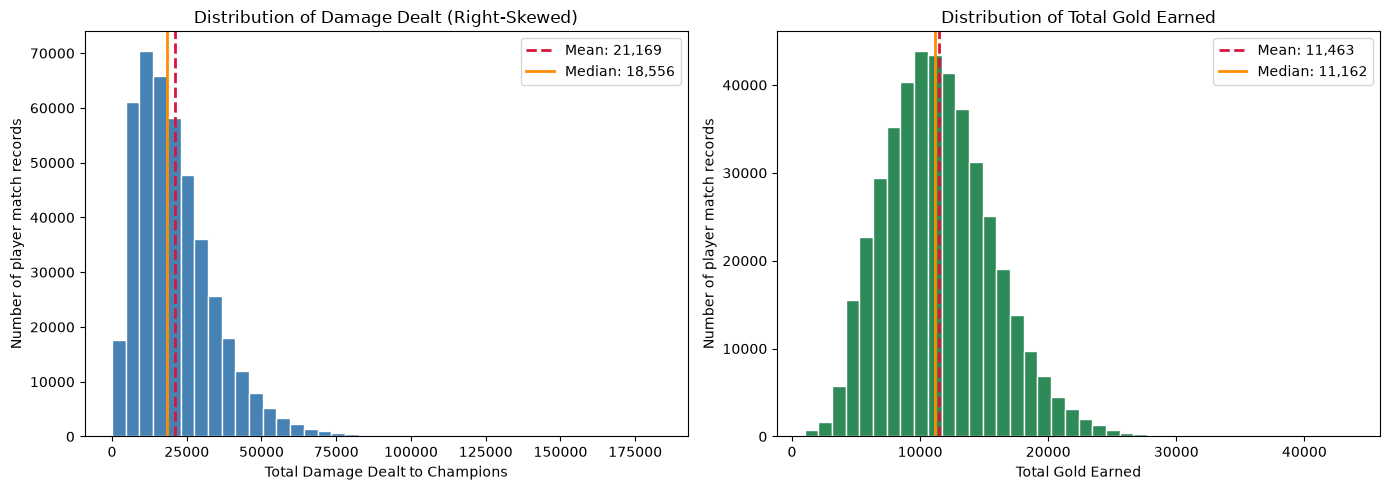

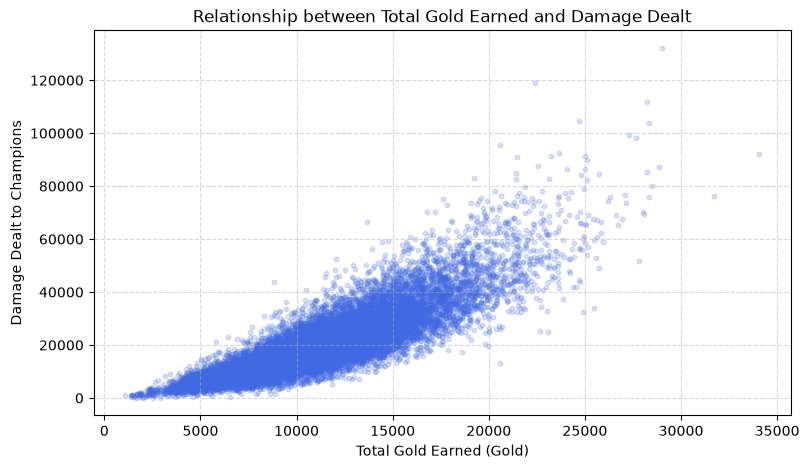

--- Pearson Linear Correlation Matrix ---


,TotalGold,DmgDealt,DmgTaken,MinionsKilled,TurretDmgDealt,kills,deaths,assists,visionScore,Win
TotalGold,1.000,0.861,0.622,0.518,0.357,0.769,0.267,0.310,0.096,0.200
DmgDealt,0.861,1.000,0.583,0.532,0.340,0.764,0.285,0.241,0.020,0.142
DmgTaken,0.622,0.583,1.000,0.165,0.137,0.358,0.542,0.285,0.172,-0.081
MinionsKilled,0.518,0.532,0.165,1.000,0.426,0.316,0.104,-0.175,-0.310,0.025
TurretDmgDealt,0.357,0.340,0.137,0.426,1.000,0.295,-0.009,-0.040,-0.055,0.202
kills,0.769,0.764,0.358,0.316,0.295,1.000,0.057,0.079,-0.092,0.264
deaths,0.267,0.285,0.542,0.104,-0.009,0.057,1.000,0.143,0.184,-0.376
assists,0.310,0.241,0.285,-0.175,-0.040,0.079,0.143,1.000,0.589,0.303
visionScore,0.096,0.020,0.172,-0.310,-0.055,-0.092,0.184,0.589,1.000,0.044
Win,0.200,0.142,-0.081,0.025,0.202,0.264,-0.376,0.303,0.044,1.000


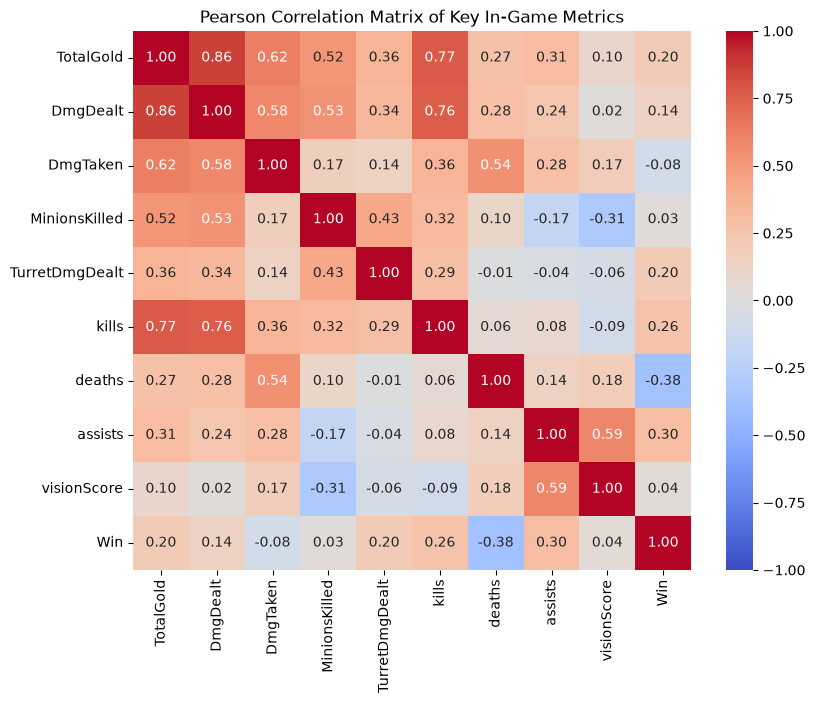

In [5]:
# only classic game mode and no remakes
classic_mask = (lol_data["QueueType"] == "CLASSIC") & (lol_data["GameDuration"] >= 300)
df_classic = lol_data.loc[classic_mask].copy() if classic_mask.sum() > 0 else lol_data.copy()

print(f"Analyzing {len(df_classic):,} valid match records.")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram DmgDealt
axes[0].hist(df_classic["DmgDealt"], bins=40, color="steelblue", edgecolor="white")
axes[0].axvline(df_classic["DmgDealt"].mean(), color="crimson", linestyle="--", linewidth=2, label=f"Mean: {df_classic['DmgDealt'].mean():,.0f}")
axes[0].axvline(df_classic["DmgDealt"].median(), color="darkorange", linestyle="-", linewidth=2, label=f"Median: {df_classic['DmgDealt'].median():,.0f}")
axes[0].set_xlabel("Total Damage Dealt to Champions")
axes[0].set_ylabel("Number of player match records")
axes[0].set_title("Distribution of Damage Dealt (Right-Skewed)")
axes[0].legend()

# Histogram TotalGold
axes[1].hist(df_classic["TotalGold"], bins=40, color="seagreen", edgecolor="white")
axes[1].axvline(df_classic["TotalGold"].mean(), color="crimson", linestyle="--", linewidth=2, label=f"Mean: {df_classic['TotalGold'].mean():,.0f}")
axes[1].axvline(df_classic["TotalGold"].median(), color="darkorange", linestyle="-", linewidth=2, label=f"Median: {df_classic['TotalGold'].median():,.0f}")
axes[1].set_xlabel("Total Gold Earned")
axes[1].set_ylabel("Number of player match records")
axes[1].set_title("Distribution of Total Gold Earned")
axes[1].legend()

plt.tight_layout()
plt.show()

# Scatterplot: TotalGold vs DmgDealt (sample of 15,000 records for clarity with big density, small s and alpha)
sample_plot = df_classic.sample(n=min(15000, len(df_classic)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(sample_plot["TotalGold"], sample_plot["DmgDealt"], s=10, alpha=0.2, color="royalblue")
ax.set_xlabel("Total Gold Earned (Gold)")
ax.set_ylabel("Damage Dealt to Champions")
ax.set_title("Relationship between Total Gold Earned and Damage Dealt")
ax.grid(True, linestyle="--", alpha=0.5)
plt.show()

# correlation analisis
corr_cols = ["TotalGold", "DmgDealt", "DmgTaken", "MinionsKilled", "TurretDmgDealt", "kills", "deaths", "assists", "visionScore", "Win"]
pearson_corr = df_classic[corr_cols].corr(method="pearson").round(3)
spearman_corr = df_classic[corr_cols].corr(method="spearman").round(3)

print("--- Pearson Linear Correlation Matrix ---")
display(pearson_corr)

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(pearson_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", ax=ax)
ax.set_title("Pearson Correlation Matrix of Key In-Game Metrics")
plt.show()

### Interpretation of the Correlation Matrix & Heatmap

#### Key Findings and Insights:
1. **Economy and Combat Power (`TotalGold` & `DmgDealt`, $r = 0.86$):**
   * There is a very strong positive correlation between total gold earned and champion damage dealt. Higher gold income allows players to purchase offensive items, which naturally scales their damage output.
   * Similarly, `kills` show strong positive correlations with both `TotalGold` ($r = 0.77$) and `DmgDealt` ($r = 0.76$), reflecting the core feedback loop of securing gold through combat participation.

2. **Role Specialization and Vision (`MinionsKilled` & `visionScore`, $r = -0.31$):**
   * The moderate negative correlation between minion kills (CS) and vision score highlights team role specialization. Players who place the most wards (Supports/Utility) intentionally leave minion farming to their carries (ADCs/Solos), resulting in a natural trade-off on the map.
   * Conversely, `assists` strongly correlate with `visionScore` ($r = 0.59$), reflecting how support and jungle roles participate in team fights while securing map control.

3. **What Drives Victory? (`Win` Row Analysis):**
   * **`deaths` ($r = -0.38$):** The strongest negative predictor of a match outcome. Frequent deaths give gold to the enemy team and remove map presence, heavily reducing the probability of winning.
   * **`assists` ($r = 0.30$) vs. `kills` ($r = 0.26$):** Interestingly, team assists correlate slightly stronger with winning than individual kills do, underlining that *League of Legends* is fundamentally a team-oriented game driven by collaborative team fights.
   * **`TurretDmgDealt` ($r = 0.20$) vs. `DmgDealt` ($r = 0.14$):** Damage dealt to structures has a higher correlation with victory than raw damage dealt to champions. This proves an analytical truth: matches are won by securing map objectives and destroying structures rather than purely fighting enemy champions.

4. **Statistical Artifacts & Confounding Variables (`TotalGold` & `deaths`, $r = 0.27$):**
   * A counter-intuitive positive correlation appears between `deaths` and `TotalGold` ($r = 0.27$) or `DmgDealt` ($r = 0.29$). In an isolated match, dying hurts your economy; however, when analyzing a dataset containing matches of various lengths, **Game Duration (`GameDuration`) acts as a major confounding variable**.
   * In short matches (e.g., 15-minute stomps), players accumulate low gold, low damage, and very few deaths. In long matches (e.g., 45+ minutes), players naturally accumulate high gold, massive damage, and significantly higher death counts. Because all these metrics scale upward with match length, they exhibit a positive linear correlation across the dataset as a whole.

5. **The Paradox of Damage Taken (`DmgTaken` & `Win`, $r = -0.08$):**
   * A counter-intuitive insight arises when analyzing damage taken: `DmgTaken` exhibits a slight negative correlation with victory. At first glance, this seems contradictory since frontline tanks are expected to absorb damage for their team.
   * **The "Bleeding Longer" Effect:** Winning teams typically dominate skirmishes and eliminate enemies quickly, meaning they take minimal counter-damage. Conversely, losing teams spend more time besieged under their towers, constantly absorbing poke and area-of-effect damage while in permanent defense. Thus, high damage taken is frequently a symptom of being behind and playing defensively.
   * **Smart vs. Reckless Absorption:** Furthermore, this dataset aggregates all champion roles—including squishy marksmen and mages. For fragile champions, high damage taken indicates poor positioning and frequent deaths. For actual tanks, victory is driven by crowd control, objective pressure (`TurretDmgDealt`, $r = 0.20$), and team assistance (`assists`, $r = 0.30$) rather than blindly soaking up damage in lost fights.

## Compare metrics across categories (`RankName` and `Lane`)

`RankFk` (`RankName` in `RankTbl.csv`) is an **ordered category** (`Unranked`, `Iron`, `Bronze`, `Silver`, `Gold`, `Platinum`, `Emerald`, `Diamond`, `Master`, `Grandmaster`, `Challenger`), while `Lane` is an **unordered category** (`TOP`, `JUNGLE`, `MIDDLE`, `BOTTOM`).
First, we must inspect **group sizes** using `.value_counts()`. Comparing a group with very few records to a massive group requires statistical caution.

--- Record counts by Rank Tier (Ordered Category) ---
RankName
Unranked       524173
Iron             3447
Bronze           9966
Silver          21111
Gold            30814
Platinum        28438
Emerald         22553
Diamond         23227
Master          40260
Grandmaster      3306
Challenger        537
Name: count, dtype: int64


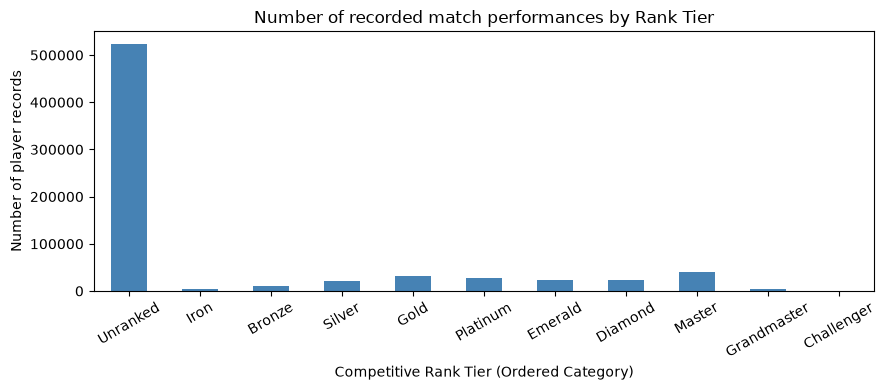


--- Record counts by Lane in CLASSIC mode ---
Lane
BOTTOM    107081
JUNGLE     88906
MIDDLE     85633
TOP        80754
Name: count, dtype: int64


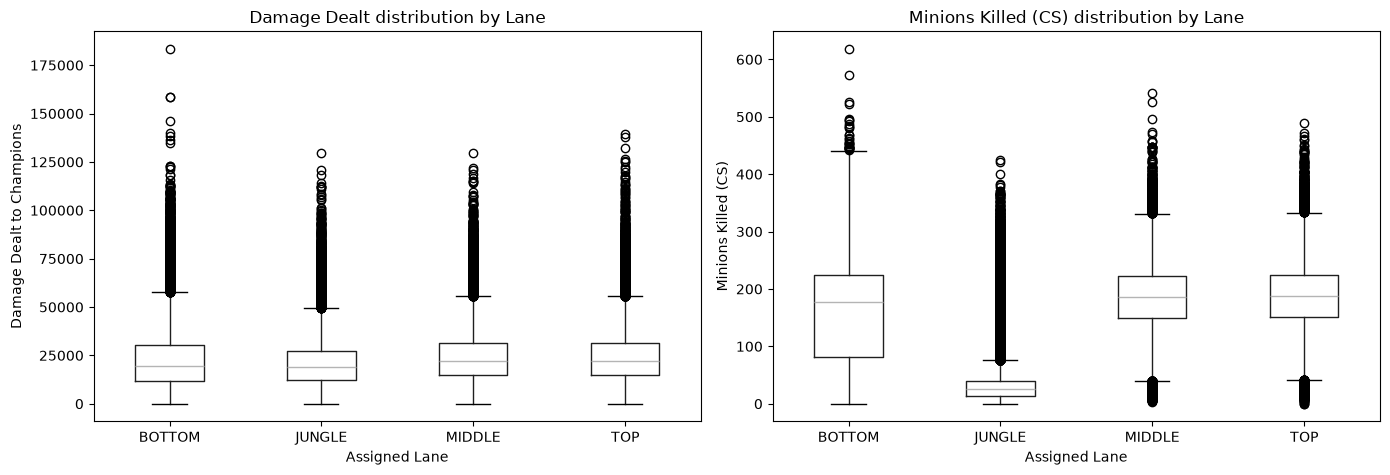

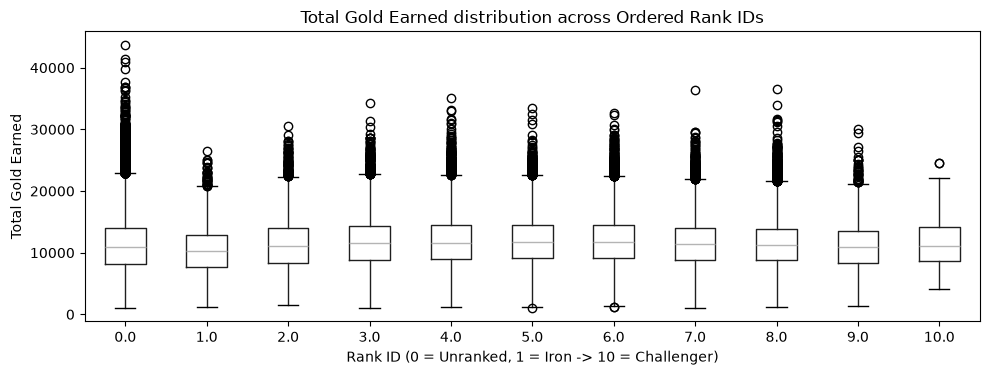

In [6]:
# how big are those groups
rank_order = rank_df.sort_values("RankId")["RankName"].tolist()
rank_counts = lol_data["RankName"].value_counts().reindex(rank_order, fill_value=0)
print("--- Record counts by Rank Tier (Ordered Category) ---")
print(rank_counts)

fig, ax = plt.subplots(figsize=(9, 4))
rank_counts.plot.bar(ax=ax, color="steelblue", rot=30)
ax.set_xlabel("Competitive Rank Tier (Ordered Category)")
ax.set_ylabel("Number of player records")
ax.set_title("Number of recorded match performances by Rank Tier")
plt.tight_layout()
plt.show()

# 2. Porównanie rozkładów DmgDealt oraz MinionsKilled względem linii (Lane) za pomocą Boxplota
valid_lanes = df_classic.loc[df_classic["Lane"].isin(["TOP", "JUNGLE", "MIDDLE", "BOTTOM"])].copy()
print("\n--- Record counts by Lane in CLASSIC mode ---")
print(valid_lanes["Lane"].value_counts())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

valid_lanes.boxplot(column="DmgDealt", by="Lane", ax=axes[0], grid=False)
axes[0].set_title("Damage Dealt distribution by Lane")
axes[0].set_xlabel("Assigned Lane")
axes[0].set_ylabel("Damage Dealt to Champions")

valid_lanes.boxplot(column="MinionsKilled", by="Lane", ax=axes[1], grid=False)
axes[1].set_title("Minions Killed (CS) distribution by Lane")
axes[1].set_xlabel("Assigned Lane")
axes[1].set_ylabel("Minions Killed (CS)")

fig.suptitle("")  # Usuwamy domyślny nadtytuł pandas
plt.tight_layout()
plt.show()

# 3. Boxplot visionScore lub TotalGold według uporządkowanej kategorii RankId (dla rang z wystarczającą próbą)
fig, ax = plt.subplots(figsize=(10, 4))
df_classic.boxplot(column="TotalGold", by="RankFk", ax=ax, grid=False)
fig.suptitle("")
ax.set_title("Total Gold Earned distribution across Ordered Rank IDs")
ax.set_xlabel("Rank ID (0 = Unranked, 1 = Iron -> 10 = Challenger)")
ax.set_ylabel("Total Gold Earned")
plt.tight_layout()
plt.show()


**Rank Tier Population vs. API Sampling (`Number of recorded match performances by Rank Tier`):**
   * The bar chart shows an extreme overrepresentation of `Unranked` (over 500k records) and `Master` tier players, while intermediate ranks (`Iron` through `Diamond`) appear relatively constrained.
   * **Data Collection Artifact:** This distribution does not reflect the natural bell-curve population of the actual *League of Legends* player base. Instead, it is an artifact of database scraping: `Unranked` captures casual/ARAM games, while `Master` entries are heavily oversampled because third-party trackers intentionally listen to high-elo ladders.

**Economic Consistency Across Ranks (`TotalGold Earned distribution across Ordered Rank IDs`):**
   * Counter-intuitively, the median total gold earned remains nearly identical across all rank tiers (~11,000 gold).
   * However, a structural shift occurs in the **outliers and whiskers**: lower ranks feature massive high-gold outliers (dots) caused by slow, dragged-out games, whereas the highest tier (`Challenger`, rank 10.0) displays a compressed distribution with fewer extreme gold spikes because high-elo matches are closed out much faster and more decisively.

**Role Specialization (`MinionsKilled (CS) distribution by Lane`):**
   * The CS boxplot clearly differentiates map roles: **Junglers** exhibit a very low, compressed median (~20–30 CS) because they farm jungle camps rather than lane minions, whereas solo lanes (`TOP`, `MIDDLE`) and `BOTTOM` cluster around 180–200 minion kills.

**The `BOTTOM` Lane Multi-Role Paradox (`Damage Dealt` & `MinionsKilled` by Lane):**
   * Despite combining two fundamentally different roles—the **Marksman (ADC)** who farms and hyper-carries with massive damage, and the **Support (Utility)** who operates on a low economy—the `BOTTOM` lane boxplots mirror the high damage output of solo lanes. The massive Interquartile Range (IQR) on `BOTTOM` captures the coexistence of these two contrasting playstyles within a single map position.

## Game Duration & Per-Minute Metrics

Raw totals (`TotalGold`, `DmgDealt`, `deaths`) are confounded by `GameDuration`: a 45-minute game naturally produces higher numbers than a 20-minute stomp. Normalizing to **per-minute** rates isolates player efficiency from match length and reveals true skill differences across ranks.

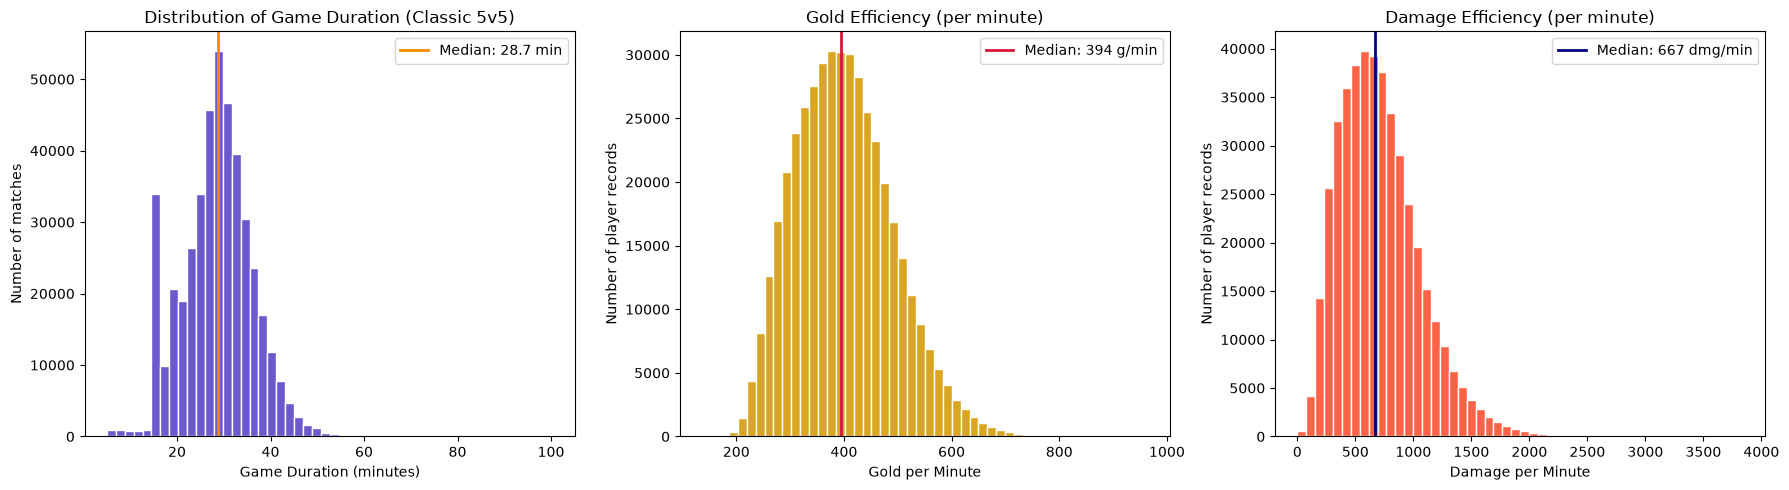

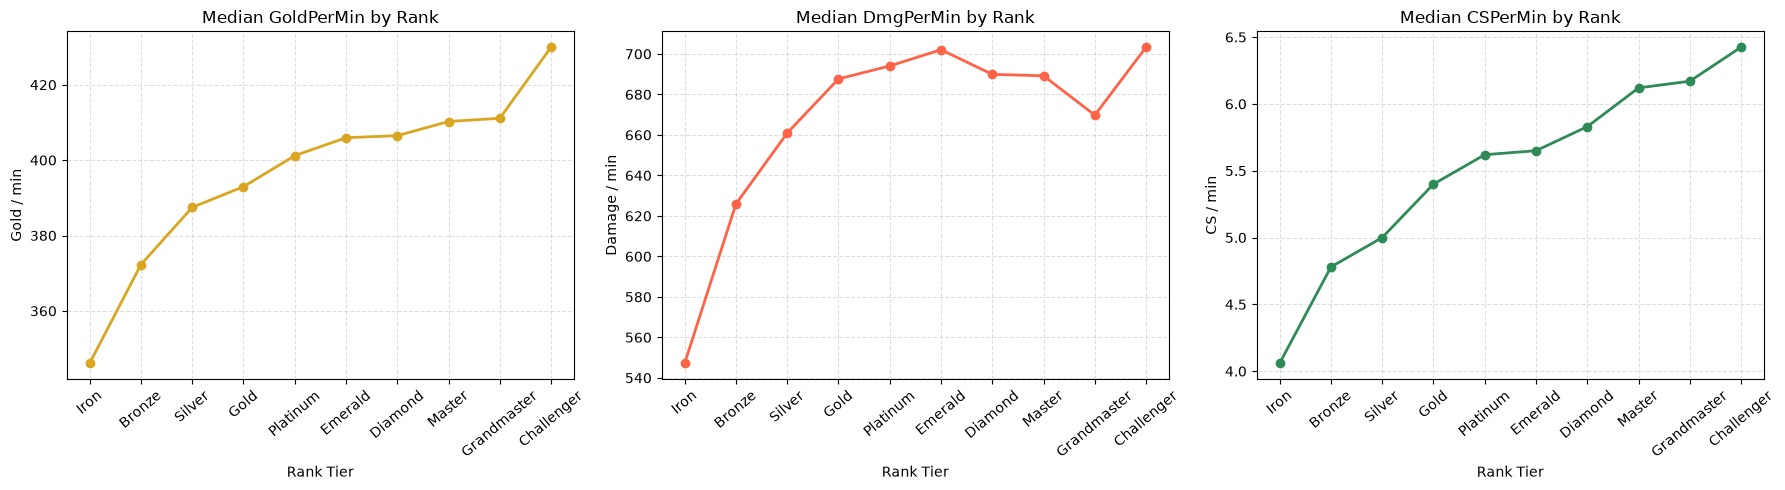

In [7]:
# per-minute normalization
df_classic["GoldPerMin"] = (df_classic["TotalGold"] / df_classic["GameDuration_min"]).round(2)
df_classic["DmgPerMin"] = (df_classic["DmgDealt"] / df_classic["GameDuration_min"]).round(2)
df_classic["CSPerMin"] = (df_classic["MinionsKilled"] / df_classic["GameDuration_min"]).round(2)
df_classic["DeathsPerMin"] = (df_classic["deaths"] / df_classic["GameDuration_min"]).round(4)

# Game Duration histogram
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df_classic["GameDuration_min"], bins=50, color="slateblue", edgecolor="white")
axes[0].axvline(df_classic["GameDuration_min"].median(), color="darkorange", linewidth=2, label=f"Median: {df_classic['GameDuration_min'].median():.1f} min")
axes[0].set_xlabel("Game Duration (minutes)")
axes[0].set_ylabel("Number of matches")
axes[0].set_title("Distribution of Game Duration (Classic 5v5)")
axes[0].legend()

# Gold per minute histogram
axes[1].hist(df_classic["GoldPerMin"], bins=50, color="goldenrod", edgecolor="white")
axes[1].axvline(df_classic["GoldPerMin"].median(), color="crimson", linewidth=2, label=f"Median: {df_classic['GoldPerMin'].median():.0f} g/min")
axes[1].set_xlabel("Gold per Minute")
axes[1].set_ylabel("Number of player records")
axes[1].set_title("Gold Efficiency (per minute)")
axes[1].legend()

# Damage per minute histogram
axes[2].hist(df_classic["DmgPerMin"], bins=50, color="tomato", edgecolor="white")
axes[2].axvline(df_classic["DmgPerMin"].median(), color="navy", linewidth=2, label=f"Median: {df_classic['DmgPerMin'].median():.0f} dmg/min")
axes[2].set_xlabel("Damage per Minute")
axes[2].set_ylabel("Number of player records")
axes[2].set_title("Damage Efficiency (per minute)")
axes[2].legend()

plt.tight_layout()
plt.show()

# Per-minute metrics by Rank (line plot)
rank_order = ["Iron", "Bronze", "Silver", "Gold", "Platinum", "Emerald", "Diamond", "Master", "Grandmaster", "Challenger"]
ranked_only = df_classic[df_classic["RankName"].isin(rank_order)].copy()
ranked_only["RankName"] = pd.Categorical(ranked_only["RankName"], categories=rank_order, ordered=True)

rank_pm = ranked_only.groupby("RankName")[["GoldPerMin", "DmgPerMin", "CSPerMin"]].median()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for i, (col, color, ylabel) in enumerate([
    ("GoldPerMin", "goldenrod", "Gold / min"),
    ("DmgPerMin", "tomato", "Damage / min"),
    ("CSPerMin", "seagreen", "CS / min"),
]):
    axes[i].plot(rank_pm.index, rank_pm[col], marker="o", color=color, linewidth=2)
    axes[i].set_xlabel("Rank Tier")
    axes[i].set_ylabel(ylabel)
    axes[i].set_title(f"Median {col} by Rank")
    axes[i].tick_params(axis="x", rotation=40)
    axes[i].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

**Efficiency Growth Over Total Wealth (`Median Gold/Min, Dmg/Min, CS/Min by Rank`):**
   * Although total accumulated gold per match is roughly equal across ranks, the **Gold-per-Minute (GPM), Damage-per-Minute, and CS-per-Minute medians steadily increase with rank** (scaling from ~4.0 CS/min in Iron to over 6.5 CS/min in Challenger).
   * **Conclusion:** Higher-ranked players accumulate resources faster and exhibit superior mechanical efficiency, resource management, and map pressure over time.

**The Challenger Data Artifact (Small Sample Size & DPM Spike):**
   * On the *Median DmgPerMin by Rank* chart, a peculiar dip occurs at Grandmaster, followed by a sudden, sharp spike at the **Challenger** tier.
   * **Statistical Artifact (Not a Gameplay Trend):** While players naturally become more efficient as rank increases, this dramatic upward surge at the very end of the curve does not represent a genuine macro-gameplay rule. Instead, it is a **statistical anomaly driven by a very small sample size** in the Challenger/Grandmaster brackets within this specific Kaggle dataset. With fewer matches sampled at the absolute apex, outlier games or scraper biases disproportionately pull the median upward, highlighting a classic limitation of small sample subsets in data science.

## Win Rate Analysis

Win rate (`Win.mean()`) is the most direct performance metric. We analyze it across **Rank**, **Lane**, and **Game Duration** buckets to uncover which positions and elo brackets consistently outperform expectations.

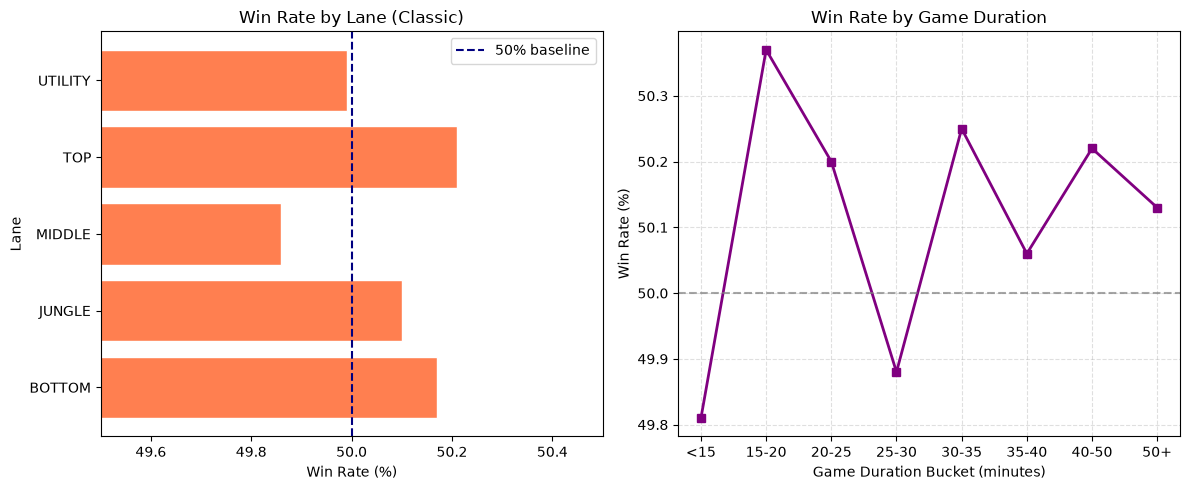

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Win rate by Lane
valid_lanes_classic = df_classic[df_classic["Lane"].isin(["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"])].copy()
wr_lane = valid_lanes_classic.groupby("Lane")["Win"].mean().round(4) * 100

axes[0].barh(wr_lane.index, wr_lane.values, color="coral", edgecolor="white")
axes[0].axvline(50, color="navy", linestyle="--", linewidth=1.5, label="50% baseline")
axes[0].set_xlim(49.5, 50.5)
axes[0].set_xlabel("Win Rate (%)")
axes[0].set_ylabel("Lane")
axes[0].set_title("Win Rate by Lane (Classic)")
axes[0].legend()

# Win rate by game duration bucket
df_classic["DurationBucket"] = pd.cut(
    df_classic["GameDuration_min"],
    bins=[0, 15, 20, 25, 30, 35, 40, 50, 120],
    labels=["<15", "15-20", "20-25", "25-30", "30-35", "35-40", "40-50", "50+"]
)
wr_dur = df_classic.groupby("DurationBucket", observed=True)["Win"].mean().round(4) * 100

axes[1].plot(wr_dur.index.astype(str), wr_dur.values, marker="s", color="purple", linewidth=2)
axes[1].axhline(50, color="gray", linestyle="--", alpha=0.7)
axes[1].set_xlabel("Game Duration Bucket (minutes)")
axes[1].set_ylabel("Win Rate (%)")
axes[1].set_title("Win Rate by Game Duration")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

#  Stacked bar: Win/Loss count by Rank
win_loss_rank = ranked_only.groupby("RankName")["Win"].value_counts().unstack(fill_value=0)
win_loss_rank.columns = ["Loss", "Win"]

when there are 2 sides to the same lane , the winrate is supposed to be 50% , same goes for the duration bucket , but the data is not balanced at all , so the winrate is skewed and not accurate at all , this is a problem with the data collection and not with the analysis

## KDA & Combat Efficiency

**KDA** = `(kills + assists) / max(1, deaths)` summarizes overall combat contribution in a single number. Analyzing KDA across roles and ranks reveals how efficiently players trade kills and how team-oriented their playstyle is.

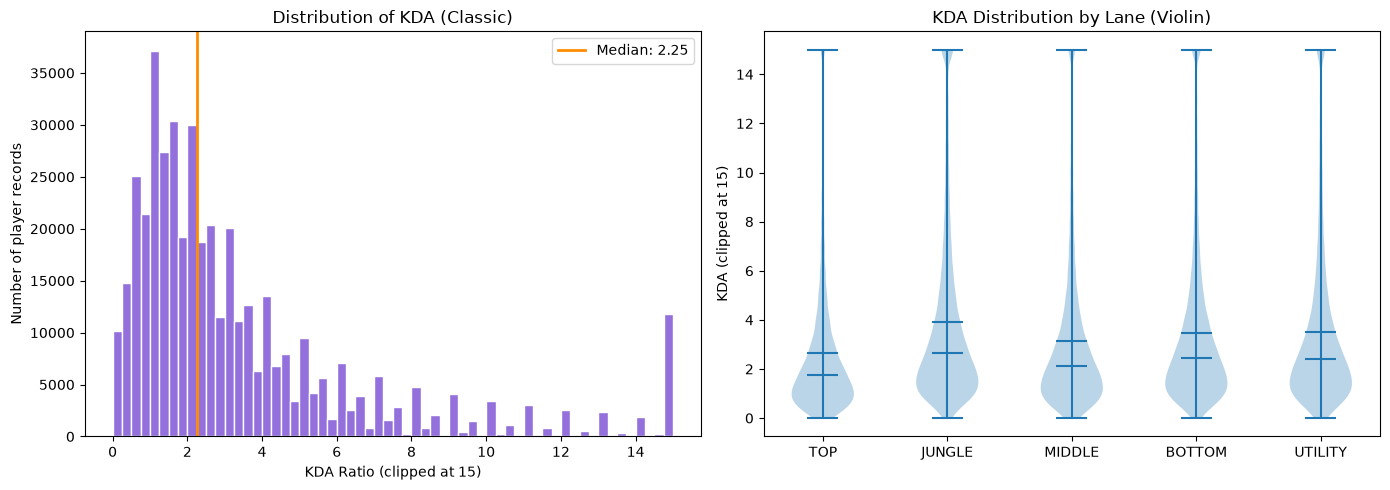

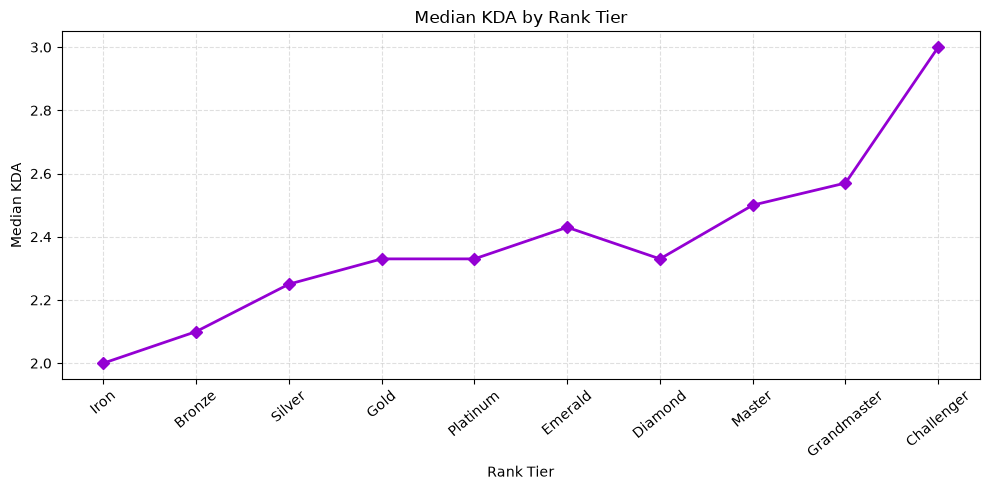

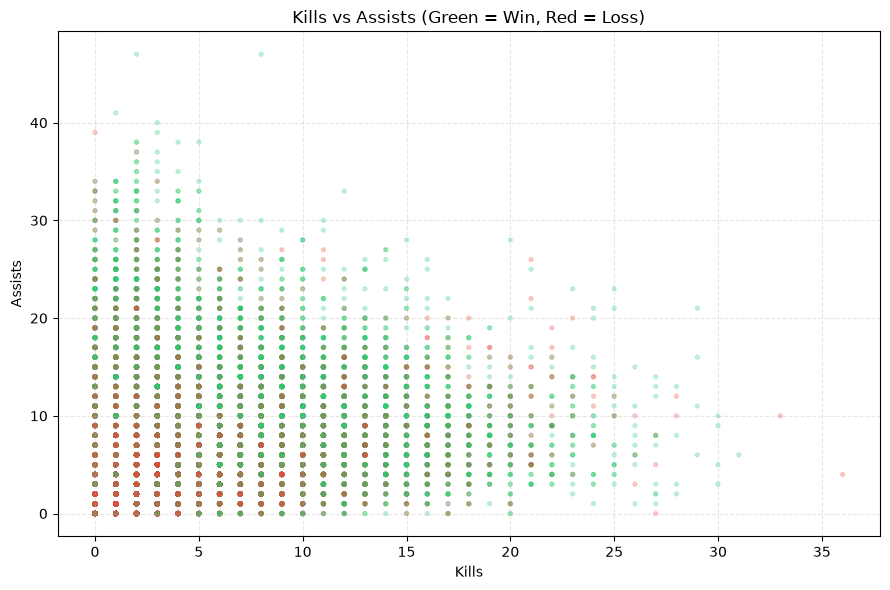

In [9]:
# KDA metric
df_classic["KDA"] = ((df_classic["kills"] + df_classic["assists"]) / df_classic["deaths"].clip(lower=1)).round(2)

# 1. KDA distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df_classic["KDA"].clip(upper=15), bins=60, color="mediumpurple", edgecolor="white")
axes[0].axvline(df_classic["KDA"].median(), color="darkorange", linewidth=2, label=f"Median: {df_classic['KDA'].median():.2f}")
axes[0].set_xlabel("KDA Ratio (clipped at 15)")
axes[0].set_ylabel("Number of player records")
axes[0].set_title("Distribution of KDA (Classic)")
axes[0].legend()

# 2. KDA by Lane (violin)
valid_kda = df_classic[df_classic["Lane"].isin(["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"])].copy()
valid_kda["KDA_clipped"] = valid_kda["KDA"].clip(upper=15)

parts = axes[1].violinplot(
    [valid_kda.loc[valid_kda["Lane"] == lane, "KDA_clipped"].values for lane in ["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"]],
    showmeans=True, showmedians=True
)
axes[1].set_xticks([1, 2, 3, 4, 5])
axes[1].set_xticklabels(["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"])
axes[1].set_ylabel("KDA (clipped at 15)")
axes[1].set_title("KDA Distribution by Lane (Violin)")

plt.tight_layout()
plt.show()

# 3. KDA by Rank (line)
kda_rank = ranked_only.copy()
kda_rank["KDA"] = ((kda_rank["kills"] + kda_rank["assists"]) / kda_rank["deaths"].clip(lower=1)).round(2)
kda_by_rank = kda_rank.groupby("RankName")["KDA"].median()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(kda_by_rank.index, kda_by_rank.values, marker="D", color="darkviolet", linewidth=2)
ax.set_xlabel("Rank Tier")
ax.set_ylabel("Median KDA")
ax.set_title("Median KDA by Rank Tier")
ax.tick_params(axis="x", rotation=40)
ax.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

# 4. Kills vs Assists scatter (Winners vs Losers)
sample_ka = df_classic.sample(n=min(20000, len(df_classic)), random_state=42)

fig, ax = plt.subplots(figsize=(9, 6))
colors = sample_ka["Win"].map({1: "#2ecc71", 0: "#e74c3c"})
ax.scatter(sample_ka["kills"], sample_ka["assists"], c=colors, s=8, alpha=0.25)
ax.set_xlabel("Kills")
ax.set_ylabel("Assists")
ax.set_title("Kills vs Assists (Green = Win, Red = Loss)")
ax.grid(True, linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

## Vision Score

Vision (ward placement and clearing) is a core Support/Jungle responsibility. Filtering to Classic 5v5 removes ARAM's artificial zeroes and exposes the true relationship between vision control and winning.

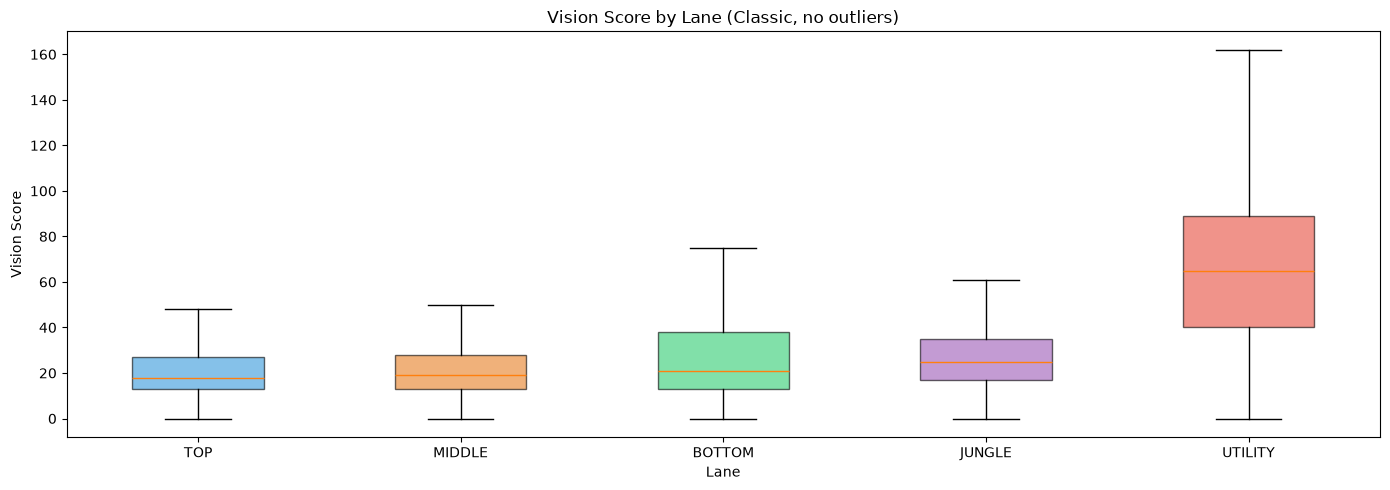

In [10]:

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

vision_lanes = df_classic[df_classic["Lane"].isin(["TOP", "JUNGLE", "MIDDLE", "BOTTOM", "UTILITY"])].copy()
lane_order = ["TOP", "MIDDLE", "BOTTOM", "JUNGLE", "UTILITY"]
vision_data = [vision_lanes.loc[vision_lanes["Lane"] == l, "visionScore"].values for l in lane_order]
bp = axes.boxplot(vision_data, tick_labels=lane_order, patch_artist=True, showfliers=False)
lane_colors = ["#3498db", "#e67e22", "#2ecc71", "#9b59b6", "#e74c3c"]
for patch, color in zip(bp["boxes"], lane_colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.6)
axes.set_xlabel("Lane")
axes.set_ylabel("Vision Score")
axes.set_title("Vision Score by Lane (Classic, no outliers)")

plt.tight_layout()
plt.show()

## Deaths Analysis & Feeding Patterns

Deaths were the strongest negative predictor of winning ($r = -0.38$). We explore how death counts distribute, the concept of "feeding" (excessive deaths), and how death rates change across ranks.

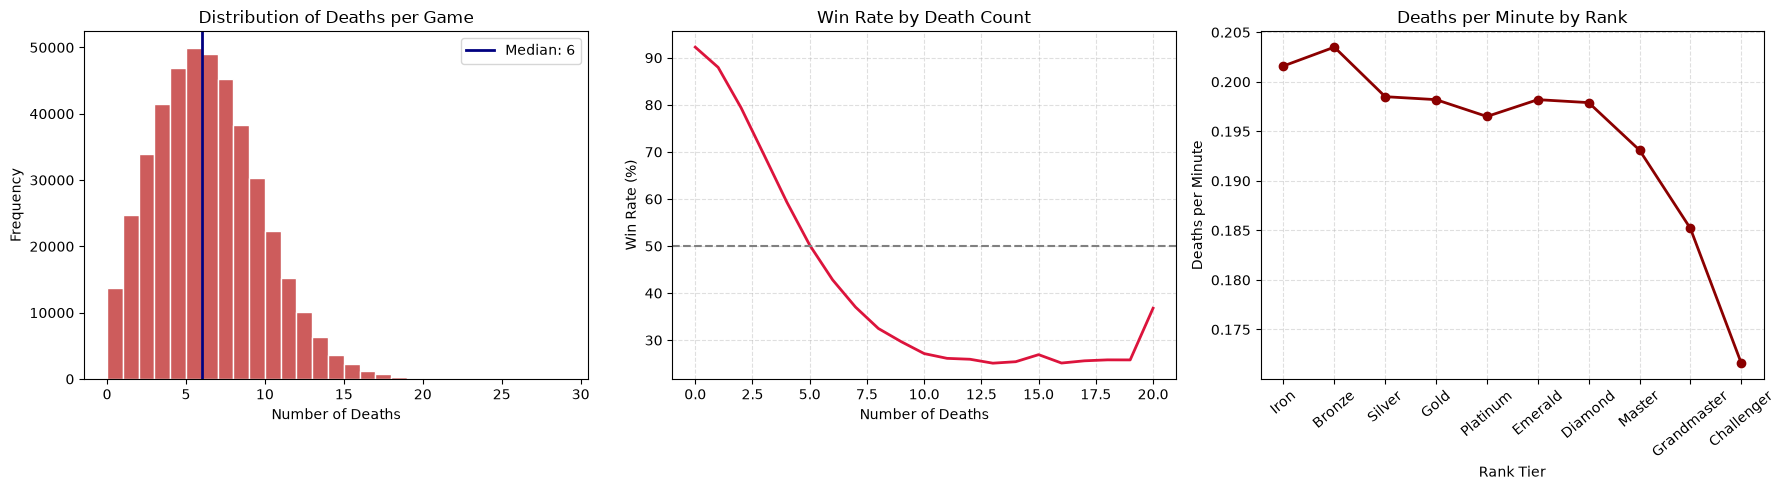

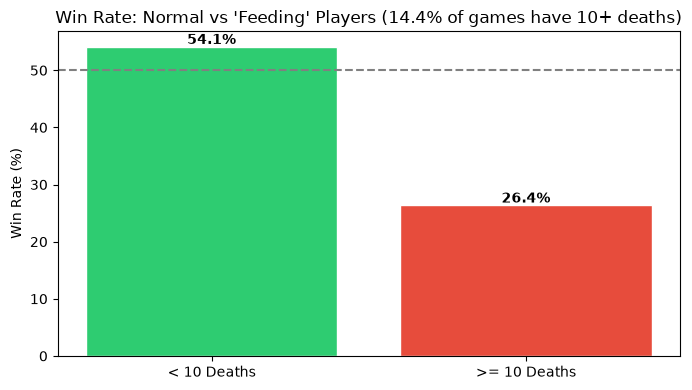

In [12]:
# 1. Deaths distribution
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df_classic["deaths"], bins=range(0, 30), color="indianred", edgecolor="white")
axes[0].axvline(df_classic["deaths"].median(), color="navy", linewidth=2, label=f"Median: {df_classic['deaths'].median():.0f}")
axes[0].set_xlabel("Number of Deaths")
axes[0].set_ylabel("Frequency")
axes[0].set_title("Distribution of Deaths per Game")
axes[0].legend()

# 2. Win rate by death count
death_wr = df_classic.groupby("deaths").agg(games=("Win", "count"), winrate=("Win", "mean"))
death_wr = death_wr[death_wr["games"] >= 100]
death_wr["winrate_pct"] = death_wr["winrate"] * 100

axes[1].plot(death_wr.index, death_wr["winrate_pct"], color="crimson", linewidth=2)
axes[1].axhline(50, color="gray", linestyle="--")
axes[1].set_xlabel("Number of Deaths")
axes[1].set_ylabel("Win Rate (%)")
axes[1].set_title("Win Rate by Death Count")
axes[1].grid(True, linestyle="--", alpha=0.4)

# 3. Deaths per minute by Rank
dpm_rank = ranked_only.copy()
dpm_rank["DeathsPerMin"] = (dpm_rank["deaths"] / dpm_rank["GameDuration_min"]).round(4)
dpm_rank_med = dpm_rank.groupby("RankName")["DeathsPerMin"].median()

axes[2].plot(dpm_rank_med.index, dpm_rank_med.values, marker="o", color="darkred", linewidth=2)
axes[2].set_xlabel("Rank Tier")
axes[2].set_ylabel("Deaths per Minute")
axes[2].set_title("Deaths per Minute by Rank")
axes[2].tick_params(axis="x", rotation=40)
axes[2].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

# 4. "Feeding" threshold: players with 10+ deaths
feed_threshold = 10
feed_pct = (df_classic["deaths"] >= feed_threshold).mean() * 100
feed_wr = df_classic.loc[df_classic["deaths"] >= feed_threshold, "Win"].mean() * 100
normal_wr = df_classic.loc[df_classic["deaths"] < feed_threshold, "Win"].mean() * 100

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(["< 10 Deaths", ">= 10 Deaths"], [normal_wr, feed_wr], color=["#2ecc71", "#e74c3c"], edgecolor="white")
ax.axhline(50, color="gray", linestyle="--")
ax.set_ylabel("Win Rate (%)")
ax.set_title(f"Win Rate: Normal vs 'Feeding' Players ({feed_pct:.1f}% of games have 10+ deaths)")
for bar, val in zip(bars, [normal_wr, feed_wr]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5, f"{val:.1f}%", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()